# 01. Ingestão, qualidade e limpeza dos dados

**Fases 1 e 2 do pipeline: ingestão, transformação e enriquecimento.**

Toda a lógica está em `src/sinistros/limpeza.py`, `vias.py` e `externos.py`; aqui mostramos cada
decisão e seu efeito.

## 1. Configuração do ambiente

In [1]:
import sys
import warnings
from pathlib import Path

# Encontra a raiz do projeto (a pasta que contém src/sinistros) e importa o pacote
raiz = Path.cwd()
while not (raiz / "src" / "sinistros").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

from sinistros import config, limpeza, analises as an, graficos as gr

## 2. Problema e perguntas

**Problema.** Fortaleza registrou cerca de 130 mil sinistros de trânsito entre 2015 e 2024, com quase
2 mil mortes. Para orientar fiscalização, engenharia e campanhas, é preciso saber **quando, onde,
com quais veículos e em que condições** os acidentes acontecem e, principalmente, quando matam.

**Perguntas.**
1. Como o volume de acidentes e de mortes evoluiu na década?
2. Em que horários e dias os acidentes são mais frequentes e mais letais?
3. Quais bairros e vias concentram acidentes e mortes, considerando população e malha viária?
4. Quais veículos estão envolvidos e quais combinações são mais letais?
5. As características do local (controle de tráfego, tipo de cruzamento) se associam à gravidade?

## 3. Carga dos dados

In [2]:
bruto = pd.read_csv(config.ARQ_BRUTO, low_memory=False)
print(bruto.shape)
bruto.head()

(130820, 27)


,data,horaint,faixahoraria,bairro,rua,numero,latitude,longitude,tipocruzamento,controletrafego,usosolo,natureza,severidade,mortos,feridos,ilesos,automovel,onibus,bicicleta,caminhao,microonibus,ciclomotor,motocicleta,tracaoanimal,trem,totalveiculos,fimdesemana
0,2015-01-01,0,Madrugada: 0 até 6,itaperi,avenida dr silas munguba,não informado,-3.78,-38.56,meio de quadra,não informado,longo da via,colisão,ferido,0,2,0,1,0,0,0,0,0,1,0,0,2,não
1,2015-01-01,0,Madrugada: 0 até 6,vila união,rua goncalo souto,não informado,-3.77,-38.53,meio de quadra,não informado,longo da via,colisão,ferido,0,2,0,0,0,0,0,0,0,0,0,0,0,não
2,2015-01-01,0,Madrugada: 0 até 6,centro,rua antonio pompeu,não informado,-3.73,-38.53,não informado,não informado,cruzamento,colisão,ferido,0,2,0,0,1,1,0,0,0,0,0,0,2,não
3,2015-01-01,1,Madrugada: 0 até 6,meireles,rua ten benevolo,não informado,-3.73,-38.51,cruzamento,semáforo,cruzamento,colisão transversal,fatal,1,2,0,0,1,0,0,0,0,1,0,0,2,não
4,2015-01-01,2,Madrugada: 0 até 6,jangurussu,avenida castelo de castro,680,-3.84,-38.52,meio de quadra,não informado,longo da via,queda,ferido,0,2,0,0,0,0,0,0,0,1,0,0,1,não


In [3]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 130820 entries, 0 to 130819
Data columns (total 27 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   data             130820 non-null  str    
 1   horaint          130820 non-null  int64  
 2   faixahoraria     130820 non-null  str    
 3   bairro           130820 non-null  str    
 4   rua              130815 non-null  str    
 5   numero           130820 non-null  str    
 6   latitude         130820 non-null  float64
 7   longitude        130820 non-null  float64
 8   tipocruzamento   130820 non-null  str    
 9   controletrafego  130820 non-null  str    
 10  usosolo          130820 non-null  str    
 11  natureza         130820 non-null  str    
 12  severidade       130820 non-null  str    
 13  mortos           130820 non-null  int64  
 14  feridos          130820 non-null  int64  
 15  ilesos           130820 non-null  int64  
 16  automovel        130820 non-null  int64  
 17  on

A base recebida já passou por uma etapa de ETL anterior (no Google Drive), que removeu 3 registros
sem código do acidente (130.823 → 130.820) e derivou bairro e rua das coordenadas.

### Dados externos

Para analisar os bairros considerando a **exposição** (quantas pessoas moram ali e quanta via existe),
usamos dados que não vêm da própria base de acidentes:

| Dado | Fonte | Arquivo |
|---|---|---|
| Limites dos 121 bairros | IBGE, malha de bairros do Censo 2022 | `dados/externos/fortaleza_bairros_ibge_2022.gpkg` |
| População e área por bairro | IBGE, Censo 2022, agregados por bairro | `dados/externos/fortaleza_populacao_bairros_ibge_2022.csv` |
| Km de vias e cruzamentos por bairro | OpenStreetMap (via `osmnx`) | `dados/externos/fortaleza_malha_viaria_osm_por_bairro.csv` |

Para baixar de novo: `python scripts/baixar_dados_externos.py`.

In [4]:
from sinistros.externos import carregar_bairros

bairros = carregar_bairros()
print(f"{len(bairros)} bairros, {bairros['populacao'].sum():,} habitantes, "
      f"{bairros['km_vias'].sum():,.0f} km de vias, {bairros['cruzamentos'].sum():,.0f} cruzamentos")
bairros.drop(columns="geometry").sort_values("populacao", ascending=False).head()

121 bairros, 2,428,708 habitantes, 4,844 km de vias, 32,857 cruzamentos


,CD_BAIRRO,NM_BAIRRO,NM_SUBDIST,populacao,area_km2,cruzamentos,km_vias,bairro,chave
48,2304400061,Jangurussu,Região administrativa IX,70651,7.97,1054,144.61,Jangurussu,jangurussu
6,2304400006,Barra do Ceará,Região administrativa II,63477,4.26,797,89.16,Barra do Ceará,barra do ceara
113,2304400078,Granja Lisboa,Região administrativa XII,63420,5.21,671,109.08,Granja Lisboa,granja lisboa
76,2304400083,Mondubim,Região administrativa X,62440,7.13,923,125.93,Mondubim,mondubim
79,2304400088,Passaré,Região administrativa VI,54870,7.18,858,112.28,Passaré,passare


## 4. Qualidade dos dados

### 4.1 "Não informado" nas variáveis categóricas

O ponto mais importante da qualidade: o "não informado" **não é constante no tempo**. O controle de
tráfego falta em 36% dos registros de 2015 e em mais de 80% desde 2021; o uso do solo deixa de ser
preenchido em 2022. Isso tem duas consequências:

- qualquer teste que trate "não informado" como uma categoria normal mistura o efeito da variável
  com o efeito do **ano** (e de quem preencheu o registro);
- análises com essas variáveis valem só para a parte da base com a informação.

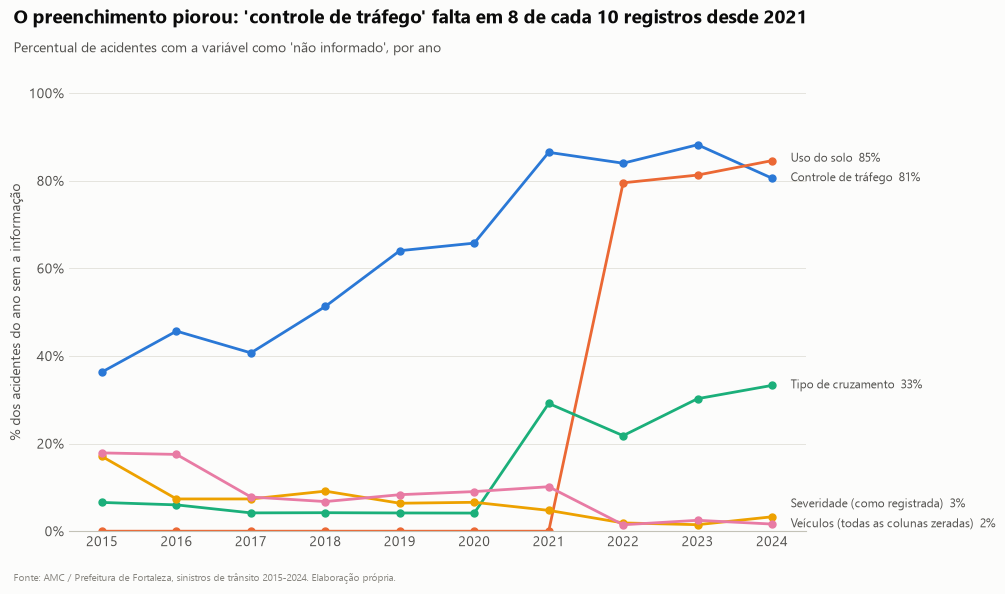

In [5]:
qualidade = an.qualidade_por_ano(limpeza.carregar())
gr.fig01_qualidade(qualidade);

In [6]:
qualidade['tabela'].round(1)

,Controle de tráfego,Uso do solo,Tipo de cruzamento,Severidade (como registrada),Veículos (todas as colunas zeradas)
ano,,,,,
2015,36.40,0.00,6.60,17.10,17.90
2016,45.70,0.00,6.00,7.40,17.50
2017,40.70,0.00,4.20,7.40,7.80
2018,51.30,0.00,4.20,9.10,6.80
2019,64.00,0.00,4.20,6.40,8.30
2020,65.80,0.00,4.10,6.60,9.00
2021,86.50,0.00,29.20,4.80,10.20
2022,84.00,79.50,21.80,1.90,1.50
2023,88.20,81.30,30.30,1.50,2.50


### 4.2 Duplicatas

In [7]:
dup = bruto[bruto.duplicated(keep=False)].sort_values(list(bruto.columns))
print(f"{bruto.duplicated().sum()} linhas são cópias exatas de outra (mesmas 27 colunas)")
dup.head(4)

54 linhas são cópias exatas de outra (mesmas 27 colunas)


,data,horaint,faixahoraria,bairro,rua,numero,latitude,longitude,tipocruzamento,controletrafego,usosolo,natureza,severidade,mortos,feridos,ilesos,automovel,onibus,bicicleta,caminhao,microonibus,ciclomotor,motocicleta,tracaoanimal,trem,totalveiculos,fimdesemana
3849,2015-03-19,3,Madrugada: 0 até 6,antônio bezerra,rd br 222,não informado,-3.74,-38.59,meio de quadra,não há controle,longo da via,colisão lateral,ileso,0,0,2,2,0,0,0,0,0,0,0,0,2,não
3850,2015-03-19,3,Madrugada: 0 até 6,antônio bezerra,rd br 222,não informado,-3.74,-38.59,meio de quadra,não há controle,longo da via,colisão lateral,ileso,0,0,2,2,0,0,0,0,0,0,0,0,2,não
4102,2015-03-24,9,Manhã: 6 até 12,cajazeiras,rd br 116,4000,-3.79,-38.51,meio de quadra,não há controle,longo da via,colisão lateral,ileso,0,0,2,1,0,0,1,0,0,0,0,0,2,não
4103,2015-03-24,9,Manhã: 6 até 12,cajazeiras,rd br 116,4000,-3.79,-38.51,meio de quadra,não há controle,longo da via,colisão lateral,ileso,0,0,2,1,0,0,1,0,0,0,0,0,2,não


São linhas idênticas em tudo: data, hora, coordenada com 6 casas decimais, via, natureza, vítimas e
veículos. Tratamos como registros duplicados e mantemos uma cópia de cada.

### 4.3 Severidade contraditória

In [8]:
pd.crosstab(bruto["severidade"], [bruto["mortos"] > 0, bruto["feridos"] > 0],
            rownames=["severidade registrada"], colnames=["houve morto", "houve ferido"])

houve morto            False        True       
houve ferido           False  True  False True 
severidade registrada                          
fatal                      0      0  1223   703
ferido                     0  94597     0     0
ileso                  21621   3434     0     0
não informado           1073   8169     0     0

- 3.434 acidentes estão como **"ileso" mas têm feridos**;
- 8.169 acidentes "não informado" têm feridos contabilizados, e só 1.073 não têm nenhuma pessoa
  contabilizada.

**Decisão:** recalcular a severidade a partir das contagens: *Fatal* se houve morto; *Ferido* se
houve ferido; *Ileso* se só houve ilesos; desconhecida se ninguém foi contabilizado. A severidade
original fica guardada em `severidade_registrada`.

### 4.4 Veículos não informados

In [9]:
sem_veiculo = bruto["totalveiculos"] == 0
print(f"{sem_veiculo.sum():,} acidentes ({sem_veiculo.mean():.1%}) têm todas as colunas de veículo zeradas")
bruto.loc[sem_veiculo, "natureza"].value_counts().head()

11,981 acidentes (9.2%) têm todas as colunas de veículo zeradas


natureza
colisão                     9901
atropelamento               1467
choque c/ obstáculo fixo     242
capotamento                   77
não informado                 76
Name: count, dtype: int64

Uma "colisão" sem nenhum veículo é impossível: esses zeros significam **veículo não informado**.
**Decisão:** marcar `veiculos_informados = False` e excluir esses acidentes de todas as análises por
tipo de veículo (antes eles entravam como acidentes "sem" automóvel, moto etc.).

## 5. Limpeza e preparação

In [10]:
df, log, mapeamento_vias = limpeza.tratar()
limpeza.salvar(df, log, mapeamento_vias)
pd.set_option("display.max_colwidth", 220)
log

,etapa,linhas_afetadas,linhas_resultantes,descricao
0,Leitura,130820,130820,Base recebida da etapa de ETL anterior (3 registros sem código do acidente já tinham sido removidos lá: 130.823 -> 130.820).
1,Duplicatas,54,130766,Linhas idênticas em todas as 27 colunas removidas (mantida 1 cópia).
2,Tempo,0,130766,"Dia da semana, fim de semana e faixa horária recalculados a partir da data e da hora e conferidos contra as colunas originais: 0 divergências."
3,Bairro,354,130766,"Bairro reatribuído pelas coordenadas com a malha oficial do IBGE (Censo 2022, 121 bairros); 385 pontos na orla ou nas divisas receberam o bairro mais próximo (até 300 m). Concordância com o bairro original: 96,2%. Li..."
4,Vias,5275,130766,"Nomes de via padronizados: 11.502 grafias -> 6.227 vias (abreviações, acentos, complementos, grafias sem tipo, erros de digitação e nomes diferentes do mesmo corredor, como CE-040 e Av. Washington Soares). Linhas afe..."
5,Categorias,17425,130766,"'tipo_cruzamento': rótulos padronizados; 'não informado' mantido como categoria própria e excluído nos testes (13,3%)."
6,Categorias,79764,130766,"'controle_trafego': rótulos padronizados; 'não informado' mantido como categoria própria e excluído nos testes (61,0%)."
7,Categorias,28510,130766,"'uso_solo': rótulos padronizados; 'não informado' mantido como categoria própria e excluído nos testes (21,8%)."
8,Categorias,1254,130766,"'natureza': rótulos padronizados; 'não informado' mantido como categoria própria e excluído nos testes (1,0%)."
9,Severidade,11601,130766,Severidade recalculada pelas contagens de vítimas: 8.167 'não informado' preenchidas e 3.434 contraditórias corrigidas (ex.: 'ileso' com feridos > 0). Ficam sem severidade 1.069 acidentes sem nenhuma pessoa contabili...


### 5.1 Severidade: registrada x recalculada

In [11]:
pd.crosstab(df['severidade_registrada'], df['severidade'].astype(str), margins=True)

severidade,Fatal,Ferido,Ileso,All
severidade_registrada,,,,
Ileso,0,3434,21607,25041
Ferido,0,94563,0,94563
Fatal,1926,0,0,1926
Não informado,0,8167,0,8167
All,1926,106164,21607,129697


### 5.2 Bairro oficial pelas coordenadas

O bairro foi reatribuído a cada acidente pelas coordenadas, com a malha **oficial** do IBGE (Censo
2022). Assim, a contagem de acidentes por bairro é compatível com a população do mesmo bairro. A
base anterior usava uma divisão um pouco diferente (tinha "Rachel de Queiroz" e não tinha "Dendê").

In [12]:
diferentes = df[df["bairro_original"].str.lower() != df["bairro"].str.lower()]
print(f"Bairro diferente do original: {len(diferentes):,} acidentes ({len(diferentes) / len(df):.1%})")
print(f"Fora do município (sem bairro): {df['bairro'].isna().sum():,}")
diferentes.groupby(["bairro_original", "bairro"]).size().sort_values(ascending=False).head(10)

Bairro diferente do original: 6,662 acidentes (5.1%)
Fora do município (sem bairro): 354


bairro_original     bairro            
tauape              São João do Tauape    1668
rachel de queiroz   Dendê                  516
jangurussu          Barroso                332
bonsucesso          Vila Peri              279
pedras              Paupina                220
cambeba             José de Alencar        191
parque santa maria  Paupina                169
ancuri              Paupina                166
sapiranga / coité   Lagoa Redonda          145
centro              Aldeota                138
dtype: int64

As maiores diferenças são de **nome** (Tauape = São João do Tauape, no IBGE) e de **divisão** (a base
antiga tinha "Rachel de Queiroz", área que na malha do IBGE é o Dendê). O restante são pontos perto
das divisas entre bairros. Descontadas as diferenças de nome, a concordância é de 96%.

### 5.3 Nomes de vias

A mesma via aparece com dezenas de grafias. A padronização (`src/sinistros/vias.py`) expande
abreviações (av → avenida, gal → general, sen → senador...), remove complementos ("- esquina com...",
"km 3", número de porta), associa grafias sem o tipo ("osorio de paiva") à via com tipo, corrige erros
de digitação só quando as palavras diferem pouco (para não juntar "Pedro I" com "Pedro II") e
unifica **nomes diferentes do mesmo corredor**, confirmados pelas coordenadas (CE-040 =
Av. Washington Soares; BR-222 = Av. Mister Hull). Todo o mapeamento fica em
`dados/processados/vias_mapeamento_nomes.csv`.

In [13]:
mapeamento_vias[mapeamento_vias["via"] == "Avenida General Osório de Paiva"].head(15)

,grafia,via,registros,regra
1355,avenida gal osorio de paiva,Avenida General Osório de Paiva,1769,exata
1356,avenida general osório de paiva,Avenida General Osório de Paiva,398,exata
1357,osorio de paiva,Avenida General Osório de Paiva,236,sem tipo
1358,general osorio de paiva,Avenida General Osório de Paiva,93,sem tipo
1359,avenida general osorio de paiva,Avenida General Osório de Paiva,72,exata
1360,avenida osorio de paiva,Avenida General Osório de Paiva,25,exata
1361,av gal osorio de paiva,Avenida General Osório de Paiva,23,exata
1362,avenida general osorio de paiva -,Avenida General Osório de Paiva,16,exata
1363,av osorio de paiva,Avenida General Osório de Paiva,12,exata
1364,av. osorio de paiva,Avenida General Osório de Paiva,3,exata


In [14]:
mapeamento_vias['regra'].value_counts()

regra
exata                                 8438
sem tipo                              2738
erro de digitação                       92
exata + mesmo corredor                  47
sem tipo + mesmo corredor               31
erro de digitação + mesmo corredor       9
Name: count, dtype: int64

## 6. Dicionário de dados (base tratada)

Base: `dados/processados/sinistros_tratados.parquet` (Parquet preserva datas e categorias).
Cada linha é um sinistro de trânsito registrado em Fortaleza entre 2015 e 2024.

| Coluna | Tipo | Descrição |
|---|---|---|
| `data` | data | Data do sinistro |
| `hora` | inteiro | Hora (0 a 23) |
| `ano`, `mes` | inteiro | Ano e mês |
| `dia_semana` | categoria ordenada | Segunda a Domingo |
| `fim_de_semana` | booleano | Sábado ou domingo |
| `faixa_horaria` | categoria ordenada | Madrugada (0h-6h), Manhã (6h-12h), Tarde (12h-18h), Noite (18h-24h) |
| `madrugada` | booleano | Faixa horária = Madrugada |
| `latitude`, `longitude` | decimal | Coordenadas do sinistro |
| `bairro`, `cd_bairro` | texto | Bairro oficial (IBGE 2022) pelas coordenadas; vazio fora do município |
| `bairro_original` | texto | Bairro da base recebida |
| `rua_original` | texto | Nome da via como registrado |
| `via` | texto | Nome padronizado da via (ou do corredor) |
| `tipo_cruzamento` | categoria | Meio de quadra, Cruzamento, T, Duplo T, Rotatória, Y, Com via férrea, Não informado |
| `controle_trafego` | categoria | Pare, Semáforo, Sem controle, Gesto (agente), Dê a preferência, Cancela, Faixa de pedestre, Não informado |
| `uso_solo` | categoria | Ao longo da via, Cruzamento, Não informado |
| `natureza` | categoria | Colisão, Queda, Atropelamento, Choque c/ obstáculo fixo... |
| `mortos`, `feridos`, `ilesos` | inteiro | Pessoas por condição |
| `vitimas` | inteiro | `mortos` + `feridos` |
| `severidade` | categoria ordenada | Recalculada: Ileso < Ferido < Fatal (vazia se ninguém foi contabilizado) |
| `severidade_registrada` | categoria | Severidade como veio na base |
| `fatal` | booleano | Houve ao menos um morto |
| `automovel` ... `tracaoanimal` | inteiro | Quantidade de cada tipo de veículo |
| `total_veiculos` | inteiro | Soma dos veículos |
| `veiculos_informados` | booleano | Falso quando todas as colunas de veículo estão zeradas |
| `envolve_moto` | booleano | Há moto ou ciclomotor (vazio se veículos não informados) |
| `perfil_veiculos` | categoria | Só automóvel, Só moto, Moto + automóvel, Envolve bicicleta, Envolve ônibus/caminhão, Outros |

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 130766 entries, 0 to 130765
Data columns (total 39 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   data                   130766 non-null  datetime64[us]
 1   hora                   130766 non-null  int64         
 2   ano                    130766 non-null  int32         
 3   mes                    130766 non-null  int32         
 4   dia_semana             130766 non-null  category      
 5   fim_de_semana          130766 non-null  bool          
 6   faixa_horaria          130766 non-null  category      
 7   madrugada              130766 non-null  bool          
 8   latitude               130766 non-null  float64       
 9   longitude              130766 non-null  float64       
 10  bairro                 130412 non-null  str           
 11  cd_bairro              130412 non-null  str           
 12  bairro_original        130766 non-null  str           
